# Doğrusal Regresyon ile Ayakkabı Numarası Tahmini

Bu çalışma kitabında, `ayakkabi_numarasi.xlsx` veri kümesinde yer alan **Kilo(kg)**, **Boy(metre)**, **Yaş** ve **Cinsiyet(E veya K)** bağımsız değişkenleri kullanılarak hedef değişken olan **Ayakkabı Numarası**nı tahmin eden bir Çoklu Doğrusal Regresyon (*Multiple Linear Regression*) modeli adım adım inşa edilecektir.

### İşlem Akışı Adımları:
1. **Kütüphanelerin Yüklenmesi**
2. **Veri Setinin Yüklenmesi ve Keşifsel Veri Analizi (EDA)**
3. **Veri Ön İşleme (Data Preprocessing)**
4. **Eğitim ve Test Kümelerine Ayırma**
5. **Modelin Oluşturulması ve Eğitilmesi**
6. **Modelin Değerlendirilmesi ve Katsayı Analizi**
7. **Örnek Girdilerle Yeni Tahmin Yapma**

## 1. Gerekli Kütüphanelerin Yüklenmesi
Veri analizi, modelleme ve metrik hesaplamaları için `pandas`, `numpy`, `matplotlib`, `seaborn` ve `scikit-learn` kütüphanelerini içe aktarıyoruz.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Grafik ayarları
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

## 2. Veri Setinin Yüklenmesi ve Keşifsel Veri Analizi (EDA)
Excel dosyasından veriyi okuyor, ilk satırları, veri tiplerini ve özet istatistikleri inceliyoruz.

In [4]:
# Excel dosyasını okuma
df = pd.read_excel('ayakkabi_numarasi.xlsx')

# İlk 5 satırı görüntüleme
print("--- İlk 5 Satır ---")
print(df.head())

# Genel bilgiler ve eksik değer kontrolü
print("\n--- Veri Bilgisi ---")
print(df.info())

# İstatiksel özet
print("\n--- İstatiksel Özet ---")
print(df.describe())

--- İlk 5 Satır ---
   Kilo(kg)  Boy(metre)  Yaş Cinsiyet(E veya K)  Ayakkabı Numarası
0        85        1.74   42                  E                 41
1        44        1.40   10                  E                 36
2        32        1.38   11                  E                 36
3        48        1.46   11                  E                 37
4        75        1.62   47                  E                 42

--- Veri Bilgisi ---
<class 'pandas.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Kilo(kg)            58 non-null     int64  
 1   Boy(metre)          58 non-null     float64
 2   Yaş                 58 non-null     int64  
 3   Cinsiyet(E veya K)  58 non-null     str    
 4   Ayakkabı Numarası   58 non-null     int64  
dtypes: float64(1), int64(3), str(1)
memory usage: 2.4 KB
None

--- İstatiksel Özet ---
         Kilo(kg)  Boy(metre)     

Cinsiyet Dağılımı:
Cinsiyet(E veya K)
E    31
K    27
Name: count, dtype: int64


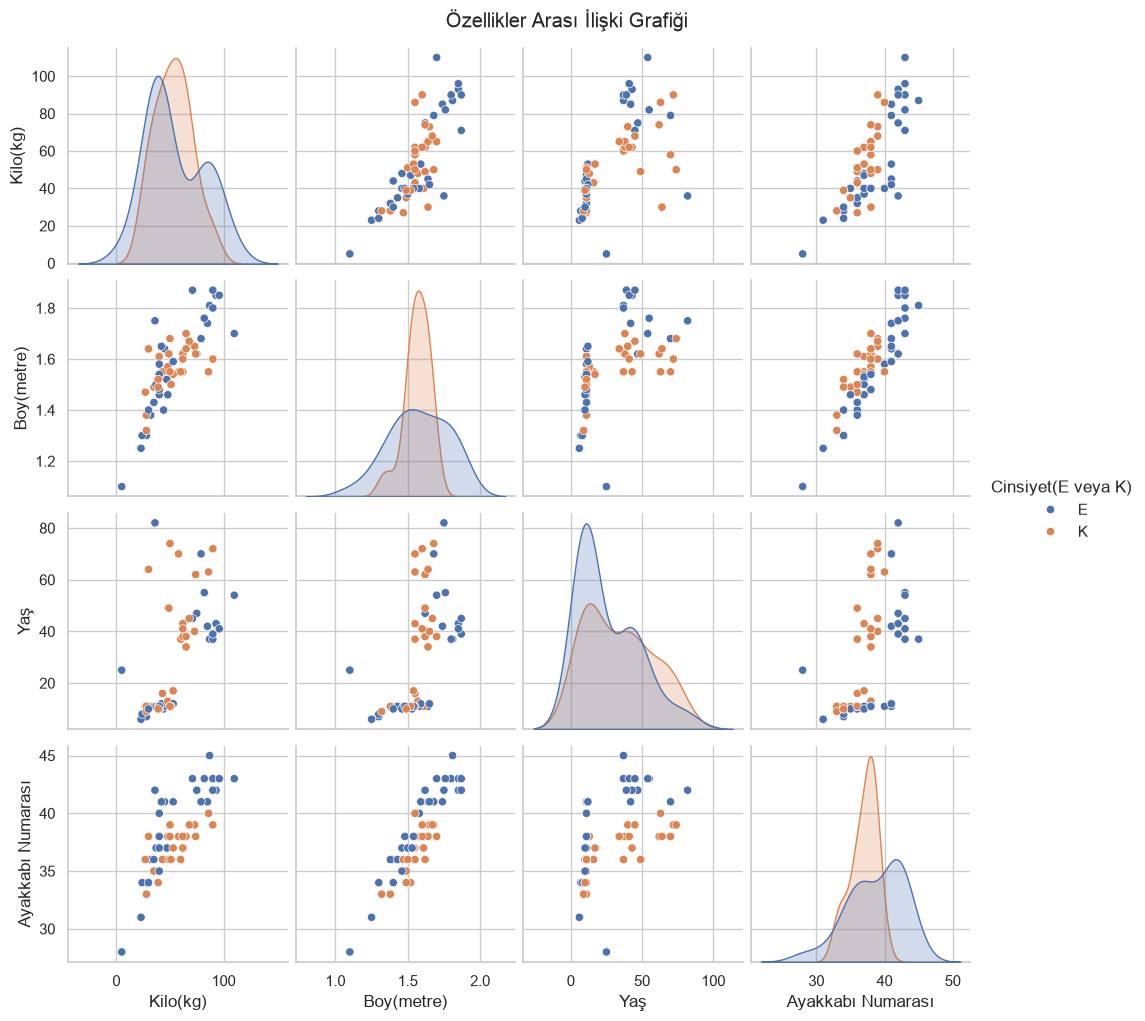

In [5]:
# Cinsiyet dağılımı
print("Cinsiyet Dağılımı:")
print(df['Cinsiyet(E veya K)'].value_counts())

# Özellikler arasındaki ilişkilerin görselleştirilmesi
sns.pairplot(df, hue='Cinsiyet(E veya K)', diag_kind='kde')
plt.suptitle("Özellikler Arası İlişki Grafiği", y=1.02)
plt.show()

## 3. Veri Ön İşleme (Data Preprocessing)
Doğrusal regresyon modelleri yalnızca sayısal girdiler kabul eder. Bu aşamada:
- `Cinsiyet(E veya K)` sütunundaki metinsel değerleri ikili (binary) formata dönüştürüyoruz (`E = 1`, `K = 0`).
- Bağımsız değişken matrisini ($X$) ve bağımlı hedef vektörünü ($y$) ayrıştırıyoruz.

In [6]:
# Cinsiyet sütununu ikili sayısal formata kodlama (E: 1, K: 0)
df['Cinsiyet_E'] = (df['Cinsiyet(E veya K)'] == 'E').astype(int)

# Bağımsız değişkenler (X) ve bağımlı değişken (y)
feature_cols = ['Kilo(kg)', 'Boy(metre)', 'Yaş', 'Cinsiyet_E']
X = df[feature_cols]
y = df['Ayakkabı Numarası']

print("X Şekli:", X.shape)
print("y Şekli:", y.shape)
print(df.head())
print(X.head())


X Şekli: (58, 4)
y Şekli: (58,)
   Kilo(kg)  Boy(metre)  Yaş Cinsiyet(E veya K)  Ayakkabı Numarası  Cinsiyet_E
0        85        1.74   42                  E                 41           1
1        44        1.40   10                  E                 36           1
2        32        1.38   11                  E                 36           1
3        48        1.46   11                  E                 37           1
4        75        1.62   47                  E                 42           1
   Kilo(kg)  Boy(metre)  Yaş  Cinsiyet_E
0        85        1.74   42           1
1        44        1.40   10           1
2        32        1.38   11           1
3        48        1.46   11           1
4        75        1.62   47           1


## 4. Eğitim ve Test Kümelerine Ayırma
Modelin daha önce görmediği veriler üzerindeki genelleme başarısını test etmek için veriyi %80 Eğitim, %20 Test olarak ikiye bölüyoruz.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Eğitim seti boyutu: {X_train.shape[0]} örnek")
print(f"Test seti boyutu:   {X_test.shape[0]} örnek")

Eğitim seti boyutu: 46 örnek
Test seti boyutu:   12 örnek


## 5. Doğrusal Regresyon Modelinin Eğitilmesi
Model aşağıdaki formülü öğrenmek üzere En Küçük Kareler (*Ordinary Least Squares*) yöntemiyle eğitilir:

$$\hat{y} = \beta_0 + \beta_1 \cdot \text{Kilo} + \beta_2 \cdot \text{Boy} + \beta_3 \cdot \text{Yaş} + \beta_4 \cdot \text{Cinsiyet\_E}$$

In [11]:
# Model nesnesinin oluşturulması ve fit edilmesi
model = LinearRegression()
model.fit(X_train, y_train)

print("Model eğitimi tamamlandı.")

Model eğitimi tamamlandı.


In [12]:
print("eğimler:",model.coef_)
print("kesme:",model.intercept_)

eğimler: [2.10043159e-02 1.59229045e+01 7.55070718e-03 1.88841372e+00]
kesme: 10.472110452061106


## 6. Modelin Değerlendirilmesi ve Katsayı Analizi
Test verisi üzerinde tahminler üreterek $R^2$, MAE (Ortalama Mutlak Hata) ve RMSE (Karekök Ortalama Kare Hata) metriklerini inceliyoruz.

In [13]:
# Test seti tahminleri
y_pred = model.predict(X_test)

# Metriklerin hesaplanması
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R² Skoru (Açıklanan Varyans Oranı): {r2:.3f}")
print(f"MAE (Ortalama Mutlak Hata):        {mae:.2f} numara")
print(f"RMSE (Karekök Ortalama Kare Hata): {rmse:.2f} numara")

# Katsayıların incelenmesi
katsayilar = pd.DataFrame({
    'Özellik': feature_cols,
    'Katsayı (Beta)': model.coef_
})
print(f"\nKesişim Noktası (Intercept / Beta_0): {model.intercept_:.4f}")
display(katsayilar)

R² Skoru (Açıklanan Varyans Oranı): 0.477
MAE (Ortalama Mutlak Hata):        1.01 numara
RMSE (Karekök Ortalama Kare Hata): 1.30 numara

Kesişim Noktası (Intercept / Beta_0): 10.4721


,Özellik,Katsayı (Beta)
0,Kilo(kg),0.021004
1,Boy(metre),15.922904
2,Yaş,0.007551
3,Cinsiyet_E,1.888414


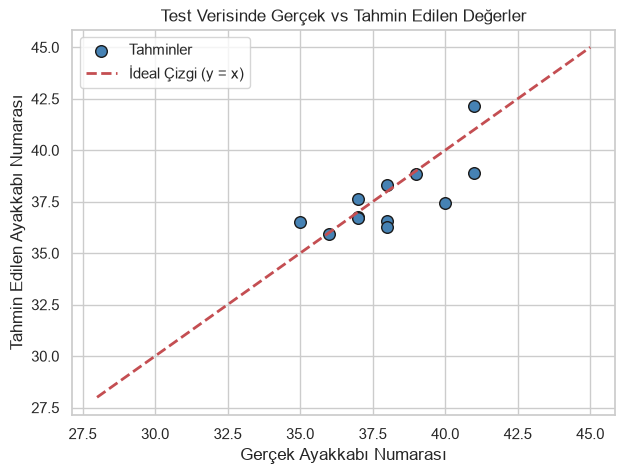

In [14]:
# Gerçek ve Tahmin Edilen Değerlerin Karşılaştırılması
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, color='steelblue', edgecolor='k', s=70, label='Tahminler')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='İdeal Çizgi (y = x)')
plt.xlabel('Gerçek Ayakkabı Numarası')
plt.ylabel('Tahmin Edilen Ayakkabı Numarası')
plt.title('Test Verisinde Gerçek vs Tahmin Edilen Değerler')
plt.legend()
plt.show()

## 7. Örnek Girdilerle Yeni Tahmin Yapma
Eğitilmiş modeli kullanarak yeni bireyler için ayakkabı numarası tahmini üretiyoruz.

In [15]:
# Örnek yeni veri: [Kilo(kg), Boy(metre), Yaş, Cinsiyet_E (1: Erkek, 0: Kadın)]
yeni_ornekler = pd.DataFrame([
    {'Kilo(kg)': 78, 'Boy(metre)': 1.76, 'Yaş': 30, 'Cinsiyet_E': 1}, # Erkek
    {'Kilo(kg)': 56, 'Boy(metre)': 1.63, 'Yaş': 25, 'Cinsiyet_E': 0}  # Kadın
])

tahminler = model.predict(yeni_ornekler)

for i, row in yeni_ornekler.iterrows():
    cinsiyet = 'Erkek' if row['Cinsiyet_E'] == 1 else 'Kadın'
    print(f"{cinsiyet} (Boy: {row['Boy(metre)']}m, Kilo: {row['Kilo(kg)']}kg, Yaş: {row['Yaş']}) -> "
          f"Tahmin: {tahminler[i]:.2f} (En Yakın No: {round(tahminler[i])})")

Erkek (Boy: 1.76m, Kilo: 78.0kg, Yaş: 30.0) -> Tahmin: 42.25 (En Yakın No: 42)
Kadın (Boy: 1.63m, Kilo: 56.0kg, Yaş: 25.0) -> Tahmin: 37.79 (En Yakın No: 38)
